# 03 · Consensus hotspots

Follows the "best models" and "comparing model prediction and clinical mutation" sections of the original notebook, using the out-of-fold probabilities from notebook 02:

1. model-specific vote thresholds (90% specificity on residues without a reported mutation)
2. votes per model and the number of models voting (`pred_all`)
3. consensus (≥ 3 of 5) and novel hotspots
4. comparison with the clinical mutation list (Venn, Fig. S6)
5. domains, active-site proximity, stability across CV repeats, vote-rule sensitivity, overlap with draft v7

In [1]:
%matplotlib inline
import sys, json, inspect, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from gaa_hotspot import data, network, stats, ml, figures as F
from gaa_hotspot import sss as sss_mod
from gaa_hotspot.common import AA, MODEL_ORDER, MODEL_NAMES, config, raw, read_processed, table, load_values
from gaa_hotspot.plotting import apply_style, MODEL_COLOURS, MODEL_LABELS, MODEL_SHORT, V7_MODEL_ORDER

apply_style()
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
cfg = config()
V = load_values()
print("project root:", ROOT)

project root: Pompe-GAA-Hotspots


## 1. Vote thresholds

A model votes for a residue when its mean out-of-fold probability is at or above the probability that gives 90% specificity on the 630 residues without a reported mutation, so each model flags at most 10% of them.

In [2]:
prob = read_processed("oof_probabilities.csv").set_index("residue")
y = prob.mutation_observed
spec = cfg["ml"]["vote_specificity"]
thresholds = {m: float(np.quantile(prob.loc[y == 0, m], spec)) for m in V7_MODEL_ORDER}
pd.DataFrame({"threshold": thresholds,
              "sensitivity": {m: float((prob.loc[y == 1, m] >= t).mean()) for m, t in thresholds.items()},
              "specificity": {m: float((prob.loc[y == 0, m] < t).mean()) for m, t in thresholds.items()},
              "residues flagged": {m: int((prob[m] >= t).sum()) for m, t in thresholds.items()}}).rename(index=MODEL_LABELS)

,threshold,sensitivity,specificity,residues flagged
Logistic Regression,0.7130,0.4486,0.9,159
Random Forest,0.6338,0.4439,0.9,158
k-Nearest Neighbors,0.7460,0.3318,0.9,134
Support Vector Machine,0.6980,0.4112,0.9,151
XGBoost,0.6566,0.4626,0.9,162


## 2. Votes of each model and `pred_all`

In [3]:
votes = pd.DataFrame({f"pred_{MODEL_LABELS[m]}": (prob[m] >= thresholds[m]).astype(int) for m in V7_MODEL_ORDER})
votes["pred_all"] = votes.sum(axis=1)
votes["pred_all"].value_counts().sort_index().to_frame("residues")

,residues
pred_all,
0,591
1,67
2,42
3,26
4,55
5,63


In [4]:
seq = data.structure_sequence()
for k in range(5, 0, -1):
    r = votes.index[votes.pred_all == k]
    print(f"pred_all == {k}  ({len(r)} residues):\n", " ".join(f"{seq[i]}{i}" for i in r), "\n")

pred_all == 5  (63 residues):
 C92 C127 R224 G259 A261 N280 D282 N290 Y292 H295 P296 N314 G334 G344 Y354 G359 P364 P365 G370 H372 R375 Y378 P397 D399 Q401 W402 D404 M439 D443 P444 P488 D513 G514 W516 D518 M519 N520 E521 H568 H572 N573 R594 S599 R600 S601 G607 G615 S627 G638 G643 G648 R672 N673 H674 E683 Y710 G720 T722 R725 Q743 G747 P754 D860 

pred_all == 4  (55 residues):
 Y136 L152 R190 Q247 T250 T258 E262 S294 E302 G309 S315 N316 M318 R331 G335 Y340 W367 G368 L373 C374 N403 L405 D413 G478 P522 P541 P545 T556 Y575 G576 E579 S583 G605 H606 A610 G611 H612 W613 T614 D645 C647 Q682 P684 R702 Y703 P726 T753 P768 N815 R819 G821 P825 T833 G855 G862 

pred_all == 3  (26 residues):
 R106 C108 L179 H180 T234 H308 A317 D319 S332 D338 P361 L369 Y407 M408 R436 I441 D489 F490 W499 T602 L637 A644 P669 N675 P707 W772 

pred_all == 2  (42 residues):
 R89 P94 C103 Y209 L231 L278 W279 R281 G293 S329 F396 D406 T415 A445 G461 G483 N492 W498 M515 I517 S523 N524 Y543 Q563 A586 F596 V597 V617 W621 N635 P64

In [5]:
stored = pd.read_csv(table("residue_votes.csv")).set_index("residue")
print("identical to results/tables/residue_votes.csv:", bool((stored.votes == votes.pred_all).all()))
stored["class"].value_counts().to_frame("residues")

identical to results/tables/residue_votes.csv: True


,residues
class,
Not prioritised,578
"Known mutation position, below consensus",122
"Consensus, known mutation position",92
Novel consensus hotspot,52


## 3. Comparing model prediction and clinical mutation

In [6]:
def find_counts(list1, list2):
    set1, set2 = set(list1), set(list2)
    print(f"Count of common numbers: {len(set1 & set2)}")
    print(f"Count of unique numbers in list1 (clinical only): {len(set1 - set2)}")
    print(f"Count of unique numbers in list2 (model only = novel hotspots): {len(set2 - set1)}")
    print(f"Unique numbers in list2: {sorted(set2 - set1)}")

known = y.index[y == 1].tolist()
predicted = votes.index[votes.pred_all >= cfg["ml"]["consensus_min_votes"]].tolist()
find_counts(known, predicted)

Count of common numbers: 92
Count of unique numbers in list1 (clinical only): 122
Count of unique numbers in list2 (model only = novel hotspots): 52
Unique numbers in list2: [92, 136, 152, 179, 180, 247, 250, 258, 280, 282, 294, 296, 302, 315, 317, 319, 331, 332, 338, 340, 344, 354, 364, 365, 368, 370, 378, 399, 402, 407, 441, 443, 488, 516, 518, 541, 606, 637, 669, 673, 683, 703, 707, 710, 720, 722, 747, 753, 754, 815, 821, 833]


### Supplementary Figure S6

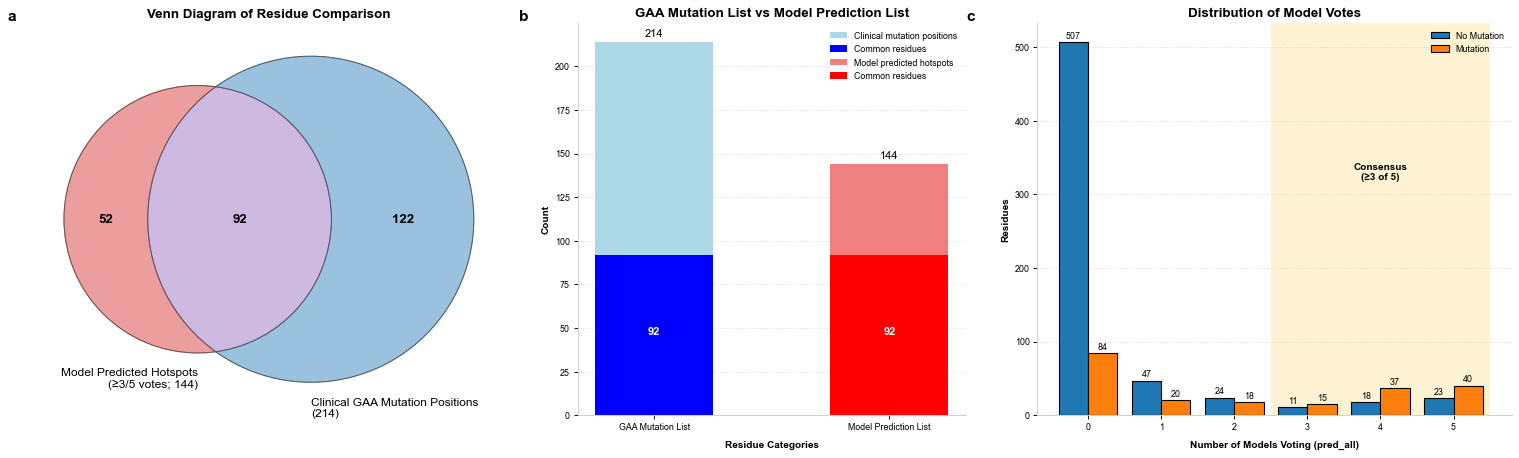

In [7]:
F.figS_predicted_vs_clinical(stored, cfg["ml"]["consensus_min_votes"])
plt.show()

## 4. Novel consensus hotspots

In [8]:
novel = pd.read_csv(table("novel_hotspots.csv")).set_index("residue")
print(len(novel), "novel hotspots; votes:", novel.votes.value_counts().sort_index().to_dict())
novel[["residue_label", "domain", "votes", "mean_probability", "consensus_repeat_fraction", "criticality", "areaSAS", "conservation",
       "nearest_active_site_residue", "nearest_active_site_distance_A"]].round(3)

52 novel hotspots; votes: {3: 11, 4: 18, 5: 23}


,residue_label,domain,votes,mean_probability,consensus_repeat_fraction,criticality,areaSAS,conservation,nearest_active_site_residue,nearest_active_site_distance_A
residue,,,,,,,,,,
92,C92,Trefoil type-P,5,0.781,1.0,Other,0.000,-1.438,Asp282 (substrate binding),29.583
136,Y136,Trefoil type-P,4,0.774,1.0,Other,0.281,-1.432,Asp282 (substrate binding),32.239
152,L152,N-terminal beta-sheet,4,0.752,1.0,Other,-0.000,-1.074,Arg600 (substrate binding),34.367
179,L179,N-terminal beta-sheet,3,0.671,0.6,Other,0.220,-0.392,Arg600 (substrate binding),27.398
180,H180,N-terminal beta-sheet,3,0.682,0.6,Other,18.990,-0.882,Arg600 (substrate binding),25.661
247,Q247,N-terminal beta-sheet,4,0.742,1.0,Other,3.065,-1.043,Asp282 (substrate binding),24.705
250,T250,N-terminal beta-sheet,4,0.727,1.0,Other,1.772,-0.974,Arg600 (substrate binding),26.895
258,T258,N-terminal beta-sheet,4,0.734,1.0,Other,1.856,-0.912,Trp613 (substrate binding),16.868
280,N280,N-terminal beta-sheet,5,0.860,1.0,Other,1.261,-1.004,Asp282 (substrate binding),4.571


## 5. Domain distribution

Observed number of novel hotspots per domain against the number expected from domain size (two-sided binomial test):

In [9]:
pd.read_csv(table("hotspot_domain_breakdown.csv")).round(3)

,domain,range,residues_in_structure,novel_hotspots,percent_of_novel,expected_by_size,binomial_p
0,Trefoil type-P,81-136,49,2,3.846,3.019,0.769
1,N-terminal beta-sheet,137-357,214,20,38.462,13.185,0.037
2,Catalytic (beta/alpha)8 barrel,358-720,363,23,44.231,22.365,0.889
3,Proximal beta-sheet,721-820,87,5,9.615,5.360,1.000
4,Distal beta-sheet,821-952,131,2,3.846,8.071,0.019


## 6. Active-site proximity

Minimum heavy-atom distance to the catalytic nucleophile D518, the acid/base D616 and the substrate-binding residues:

active-site residues among the novel hotspots: ['D282', 'I441', 'W516', 'D518']
novel hotspots within 8 Å of an active-site residue: 12 of 52


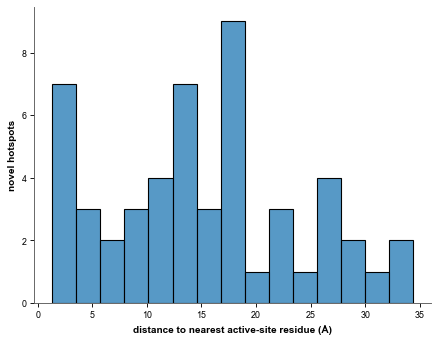

In [10]:
print("active-site residues among the novel hotspots:", novel.loc[novel.is_active_site_residue, "residue_label"].tolist())
print("novel hotspots within 8 Å of an active-site residue:", int((novel.nearest_active_site_distance_A <= 8).sum()), "of", len(novel))
sns.histplot(novel.nearest_active_site_distance_A, bins=15)
plt.xlabel("distance to nearest active-site residue (Å)"); plt.ylabel("novel hotspots"); plt.show()

## 7. Stability across the five CV repeats

The consensus vote repeated separately within each CV repeat:

novel hotspots reaching consensus in all 5 repeats: 33 of 52


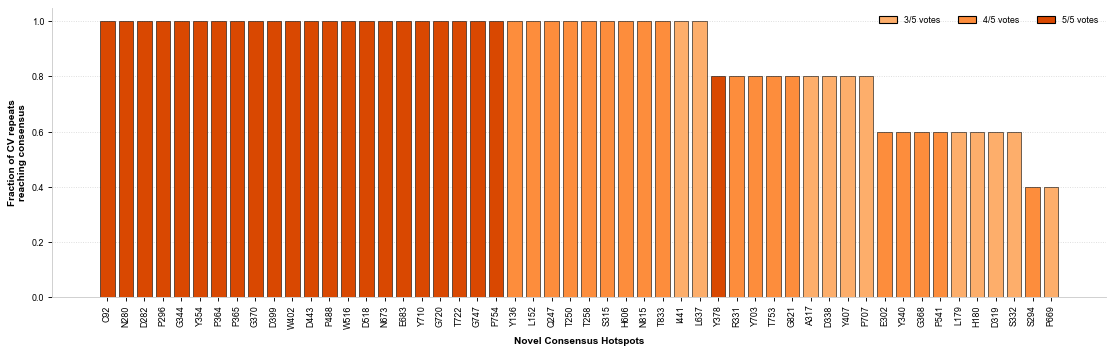

In [11]:
print("novel hotspots reaching consensus in all 5 repeats:", int((novel.consensus_repeat_fraction == 1).sum()), "of", len(novel))
F.figS_hotspot_stability(novel)
plt.show()

## 8. Sensitivity to the vote rule

In [12]:
pd.read_csv(table("vote_threshold_sensitivity.csv"))

,vote_rule,flagged_by_at_least_one_model,consensus,consensus_known_positions,novel_consensus_hotspots,novel_with_5_votes
0,probability 0.5,499,362,164,198,118
1,Youden optimum,467,367,168,199,103
2,prevalence-matched,322,201,115,86,41
3,85 % specificity,311,200,113,87,39
4,90 % specificity,253,144,92,52,23
5,95 % specificity,162,80,52,28,8


## 9. Overlap with the 42 hotspots of draft v7

In [13]:
V7 = [92, 135, 136, 244, 247, 258, 280, 282, 296, 302, 315, 317, 331, 338, 344, 353, 354, 364, 365, 370, 378, 399, 402, 407, 443,
      488, 516, 518, 597, 606, 639, 673, 683, 703, 710, 720, 722, 747, 754, 821, 833, 951]
shared = sorted(set(V7) & set(novel.index))
print(f"{len(shared)} of 42 v7 hotspots are novel consensus hotspots here")
lost = sorted(set(V7) - set(novel.index))
display(stored.loc[lost, ["wt", "votes", "class", "mean_probability"]])
print("new novel hotspots not in the v7 list:", [f"{seq[r]}{r}" for r in sorted(set(novel.index) - set(V7))])

36 of 42 v7 hotspots are novel consensus hotspots here


,wt,votes,class,mean_probability
residue,,,,
135,S,1,Not prioritised,0.5949
244,Q,1,Not prioritised,0.6589
353,Q,1,Not prioritised,0.6343
597,V,2,Not prioritised,0.6855
639,V,1,Not prioritised,0.5951
951,W,1,Not prioritised,0.6764


new novel hotspots not in the v7 list: ['L152', 'L179', 'H180', 'T250', 'S294', 'D319', 'S332', 'Y340', 'G368', 'I441', 'P541', 'L637', 'P669', 'P707', 'T753', 'N815']


## 10. Known mutation positions that no model prioritises

In [14]:
known_df = stored[stored.mutation_observed == 1]
print("known positions with 0 votes:", int((known_df.votes == 0).sum()), "  below consensus:", int((known_df.votes < 3).sum()), "of", len(known_df))
pd.read_csv(table("discordant_positions.csv")).round(4)

known positions with 0 votes: 84   below consensus: 122 of 214


,feature,median_zero_vote_positions,median_consensus_positions,mann_whitney_p
0,areaSAS,8.4068,1.1170,0.0000
1,conservation,-0.2485,-1.2140,0.0000
2,degree,9.0000,9.0000,0.0486
3,betweenness,1464.1807,2733.1352,0.0001
4,closeness,0.1457,0.1674,0.0000
